# COMP8410 A1 - Week 7: video editing - Wan2.1-VACE-1.3B vs Lucy-Edit-Dev

Matched comparison: same clips, same instructions, same seed, **480x832, 50 steps, CFG 5.0 for both**.
The one declared asymmetry is conditioning - VACE consumes a spatial edit mask, Lucy-Edit is
instruction-only. The mask box is used at *scoring* time for both models, so `bg_psnr`
(fidelity outside the edit region) is measured identically.

**Order:** 1.1 -> 2.1 -> 2.2 -> 2.3 -> 2.4 (look at the inputs!) -> 3.x smokes -> 3.3 gate -> 4.x full -> 5.x cost.
Never use Run all. Disconnect the GPU when idle.

## 1. Setup

In [1]:
# [1.1] SETUP, fresh runtime only: mount Drive, clone the repo, link results/ and outputs/ to Drive
%cd /content
import os
os.environ['HF_HOME'] = '/content/hf'
from google.colab import drive # type: ignore
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/comp8410_a1'
for d in ['results', 'outputs', 'logs']:
    os.makedirs(f'{BASE}/{d}', exist_ok=True)
!rm -rf /content/a1 && git clone https://github.com/yash1998-MQ-AI/COMP8410-A1-48576158.git /content/a1
%cd "/content/a1/48576158 Evaluation"
!rm -rf results outputs && ln -s {BASE}/results results && ln -s {BASE}/outputs outputs
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
Cloning into '/content/a1'...
remote: Enumerating objects: 535, done.
remote: Counting objects: 100% (535/535), done.
remote: Compressing objects: 100% (342/342), done.
remote: Total 535 (delta 215), reused 493 (delta 173), pack-reused 0 (from 0)
Receiving objects: 100% (535/535), 21.24 MiB | 19.88 MiB/s, done.
Resolving deltas: 100% (215/215), done.
/content/a1/48576158 Evaluation
name, memory.total [MiB]
NVIDIA L4, 23034 MiB


In [2]:
# [1.2] RESTORE after a kernel restart (use INSTEAD of 1.1; NOT after switching runtime type)
import os
os.environ['HF_HOME'] = '/content/hf'
BASE = '/content/drive/MyDrive/comp8410_a1'
%cd "/content/a1/48576158 Evaluation"
from google.colab import drive
drive.mount('/content/drive')
!git -C /content/a1 pull -q
!nvidia-smi --query-gpu=name,memory.total --format=csv

/content/a1/48576158 Evaluation
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
name, memory.total [MiB]
NVIDIA L4, 23034 MiB


## 2. Install, tests, inputs

Both models are diffusers-native (no repo to clone, no flash-attn), so 2.1 is quick.

In [3]:
# [2.1] INSTALL (diffusers >= 0.42.1 ships WanVACEPipeline and LucyEditPipeline)
%cd "/content/a1/48576158 Evaluation"
!python pairs/w7_video_editing/install_w7.py 2>&1 | tail -20

/content/a1/48576158 Evaluation
$ /usr/bin/python3 -m pip install -q -U diffusers>=0.42.1 transformers>=4.49 accelerate safetensors sentencepiece ftfy imageio[ffmpeg] imageio-ffmpeg opencv-python-headless scikit-image pandas matplotlib tabulate
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (

diffusers 0.42.1
  WanVACEPipeline: OK
  LucyEditPipeline: OK
  AutoencoderKLWan: 

In [4]:
# [2.2] CPU TESTS: the pure functions (frame counts, mask, PSNR/SSIM outside the box, flicker)
%cd "/content/a1/48576158 Evaluation"
!python -m pytest tests/test_w7.py -q 2>&1 | tail -5

/content/a1/48576158 Evaluation
..............                                                           [100%]
14 passed in 0.92s


In [5]:
# [2.3] PREPARE INPUTS -> 832x480 mp4s at a 4n+1 frame count + items.csv
# SRC = the folder holding your walkthrough clips. Options:
#   your uploaded clips:  f'{BASE}/w7_data/setD'
#   Pair 5 clips instead: 'outputs/w6/hunyuanvideo15'
%cd "/content/a1/48576158 Evaluation"
SRC = f'{BASE}/w7_data/setD'
!ls -la "{SRC}" 2>/dev/null | head -12 || echo "SRC NOT FOUND - upload the clips or point SRC at outputs/w6/hunyuanvideo15"
!python pairs/w7_video_editing/prepare_inputs.py --src "{SRC}" --limit 6 --force 2>&1 | grep -v "pix_fmt" | tail -12
print('\n--- items.csv ---')
!cat pairs/w7_video_editing/items.csv

/content/a1/48576158 Evaluation
total 239784
drwx------ 2 root root     4096 Nov  5 06:50 .
drwx------ 3 root root     4096 Nov  5 06:50 ..
-rw------- 1 root root 31519980 Nov  5 06:34 Bathroom.mp4
-rw------- 1 root root 43978316 Nov  5 06:35 Bedroom_2.mp4
-rw------- 1 root root 34127946 Nov  5 06:33 Kitchen_and_main_living_area.mp4
-rw------- 1 root root 40198841 Nov  5 06:34 Living_area.mp4
-rw------- 1 root root 32166337 Nov  5 06:34 Main_Bedroom.mp4
-rw------- 1 root root 35148772 Nov  5 06:33 Storeroom_and_gym.mp4
-rw------- 1 root root 28388278 Nov  5 06:34 Washing_machine_room.mp4
[main_bedroom] Main_Bedroom.mp4: frames 62..143 (81) 832x480  edit=furniture
         "replace the bed with a low oak platform bed with white linen"  box=(0.2, 0.42, 0.9, 0.98)
[bedroom_2] Bedroom_2.mp4: frames 87..168 (81) 832x480  edit=relight
         "relight the room with warm golden-hour sunlight through the window"  box=(0.0, 0.0, 1.0, 1.0)
[bathroom] Bathroom.mp4: frames 58..139 (81) 832x480  e

/content/a1/48576158 Evaluation
living_area       81f  832x480  box=(0.0, 0.42, 0.6, 1.0)  'replace the brown leather sofa with a dark green velvet ch'
main_bedroom      81f  832x480  box=(0.2, 0.42, 0.9, 0.98)  'replace the bed with a low oak platform bed with white lin'
bedroom_2         81f  832x480  box=(0.0, 0.0, 1.0, 1.0)  'relight the room with warm golden-hour sunlight through th'
bathroom          81f  832x480  box=(0.0, 0.0, 1.0, 1.0)  'relight the room with warm golden-hour sunlight through th'
kitchen_and_main_living_area  81f  832x480  box=(0.25, 0.6, 0.72, 1.0)  'change the floor to wide plank light oak timber flooring'
storeroom_and_gym  81f  832x480  box=(0.0, 0.68, 1.0, 1.0)  'change the floor to light grey epoxy garage flooring'


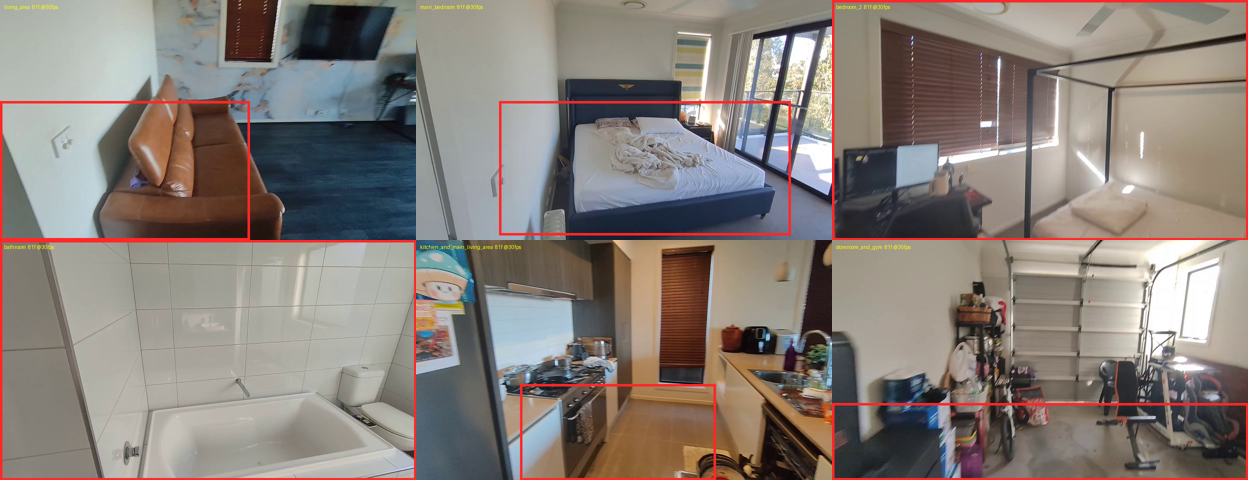

In [6]:
# [2.4] LOOK AT THE INPUTS BEFORE SPENDING GPU (W6 lesson: wrong inputs cost a whole run).
# Contact sheet: first frame of each prepared clip with its edit box drawn on.
%cd "/content/a1/48576158 Evaluation"
import sys, numpy as np
from PIL import Image, ImageDraw
sys.path.insert(0, 'pairs/w7_video_editing'); sys.path.insert(0, '.')
import w7_common as C
from prepare_inputs import read_frames
ids = C.item_ids()
tiles = []
for it in ids:
    fr, fps = read_frames(C.clip_path(it))
    im = Image.fromarray(fr[0]).copy()
    d = ImageDraw.Draw(im)
    d.rectangle(C.box_pixels(C.box_of(it)), outline=(255, 40, 40), width=5)
    d.text((8, 8), f"{it}  {len(fr)}f @{fps:.0f}fps", fill=(255, 255, 0))
    tiles.append(np.asarray(im.resize((416, 240))))
    print(f"{it:16s} {len(fr):3d}f  {fr[0].shape[1]}x{fr[0].shape[0]}  box={C.box_of(it)}  '{C.prompt_of(it)[:58]}'")
rows = [np.hstack(tiles[i:i+3]) for i in range(0, len(tiles), 3)]
w = max(r.shape[1] for r in rows)
rows = [np.pad(r, ((0,0),(0,w-r.shape[1]),(0,0))) for r in rows]
display(Image.fromarray(np.vstack(rows)))

## 3. Smoke tests and the budget gate (A100 or L4)

6 steps instead of 50 and one item, so each smoke is a couple of minutes. Check the output
clip actually changed inside the box and not outside before committing to the full run.

In [10]:
# [3.1] SMOKE wan21_vace (mask-conditioned): 1 item, 6 steps. First run downloads the model.
%cd "/content/a1/48576158 Evaluation"
!python pairs/w7_video_editing/gen_w7.py wan21_vace --smoke 2>&1 | grep -v Warning | tail -12

/content/a1/48576158 Evaluation
Loading pipeline components...: 100%|██████████| 5/5 [00:02<00:00,  1.73it/s]
[wan21_vace] loaded in 73s
100%|██████████| 6/6 [02:09<00:00, 21.51s/it]
[vost#0:0/libx264 @ 0x579605b255c0] Multiple -pix_fmt options specified for stream 0, only the last option '-pix_fmt yuv420p' will be used.
[wan21_vace] living_area s0: 197s  20.1GB  81f -> living_area_s0.mp4

finished: 1 ok, 0 failed


In [11]:
# [3.2] SMOKE lucy_edit (instruction-only): 1 item, 6 steps.
%cd "/content/a1/48576158 Evaluation"
!python pairs/w7_video_editing/gen_w7.py lucy_edit --smoke 2>&1 | grep -v Warning | tail -12

/content/a1/48576158 Evaluation
Loading pipeline components...: 100%|██████████| 5/5 [00:59<00:00, 11.97s/it]
[lucy_edit] loaded in 172s
100%|██████████| 6/6 [00:45<00:00,  7.54s/it]
[vost#0:0/libx264 @ 0x5d51746585c0] Multiple -pix_fmt options specified for stream 0, only the last option '-pix_fmt yuv420p' will be used.
[lucy_edit] living_area s0: 141s  18.1GB  81f -> living_area_s0.mp4

finished: 1 ok, 0 failed


/content/a1/48576158 Evaluation
wan21_vace   ok=True latency=197s vram=20.1GB steps=6 
lucy_edit    ok=True latency=141s vram=18.1GB steps=6 


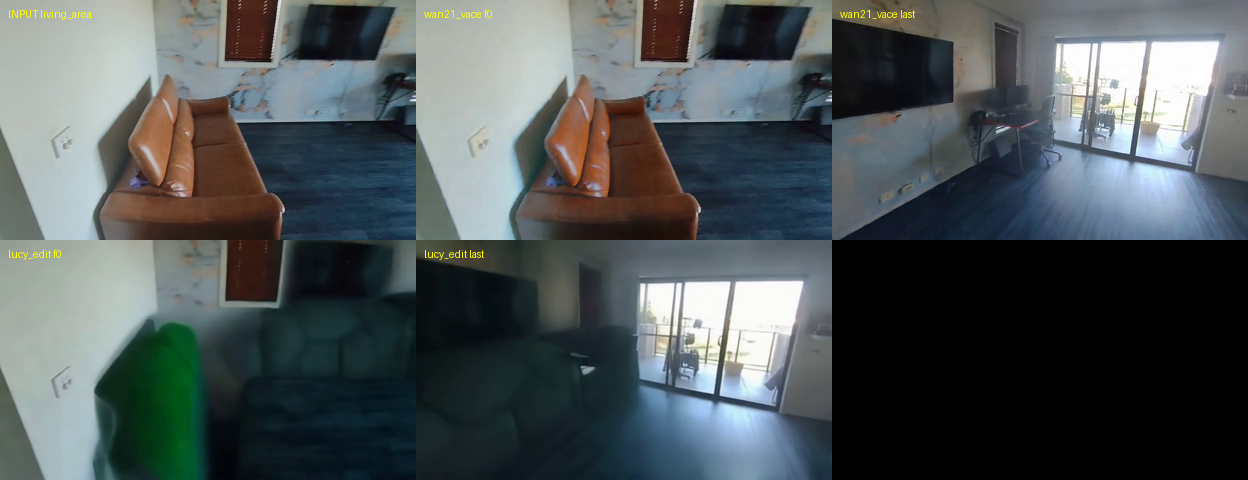


projected full run: 288 min for 6 items x 1 seed(s) x 2 models
projected cost: 56.5 units = A$8.54
set BALANCE to your remaining units for a verdict


In [12]:
# [3.3] LOOK AT THE SMOKE OUTPUTS + BUDGET GATE.
# Top row = input first frame, then each model's first and last frame. Then the projection.
%cd "/content/a1/48576158 Evaluation"
import sys, json, glob
import numpy as np
from pathlib import Path
from PIL import Image, ImageDraw
sys.path.insert(0, 'pairs/w7_video_editing'); sys.path.insert(0, '.')
import w7_common as C
from prepare_inputs import read_frames

item = C.item_ids()[0]
panels, labels = [], []
fr, _ = read_frames(C.clip_path(item))
panels += [fr[0]]; labels += [f'INPUT {item}']
lat = {}
for m in C.MODELS:
    p = Path('outputs/w7_smoke') / m / f'{item}_s0.mp4'
    side = p.with_suffix('.json')
    if side.exists():
        d = json.loads(side.read_text())
        lat[m] = d.get('latency_s')
        print(f"{m:12s} ok={d.get('ok')} latency={d.get('latency_s', 0):.0f}s vram={d.get('peak_vram_gb', 0):.1f}GB "
              f"steps={d.get('steps')} {d.get('error', '')}")
    if p.exists():
        g, _ = read_frames(p)
        panels += [g[0], g[-1]]; labels += [f'{m} f0', f'{m} last']
    else:
        print(f"{m}: NO OUTPUT at {p}")
if len(panels) > 1:
    tiles = []
    for a, lb in zip(panels, labels):
        im = Image.fromarray(a).resize((416, 240))
        ImageDraw.Draw(im).text((8, 8), lb, fill=(255, 255, 0))
        tiles.append(np.asarray(im))
    rows = [np.hstack(tiles[i:i+3]) for i in range(0, len(tiles), 3)]
    w = max(r.shape[1] for r in rows)
    display(Image.fromarray(np.vstack([np.pad(r, ((0,0),(0,w-r.shape[1]),(0,0))) for r in rows])))

# Projection: smoke used 6 steps, the full run uses C.STEPS. Sampling time scales with steps.
UNITS_PER_HR = 11.77   # A100-40GB. Change to your Resources-panel rate (T4 ~1.1, L4 ~4.8).
BALANCE = None         # <- put your remaining compute units here to get a verdict
n_items, n_seeds = len(C.item_ids()), len(C.SEEDS)
if lat:
    per_item = sum(lat.values()) * (C.STEPS / 6)          # both models, scaled to full steps
    total_s = per_item * n_items * n_seeds + 2 * 180      # + model load allowance
    units = total_s / 3600 * UNITS_PER_HR
    print(f"\nprojected full run: {total_s/60:.0f} min for {n_items} items x {n_seeds} seed(s) x 2 models")
    print(f"projected cost: {units:.1f} units = A${units*0.1513:.2f}")
    if BALANCE is not None:
        print('GATE PASSED' if units < BALANCE * 0.8 else f'GATE FAILED - reduce --limit or steps (balance {BALANCE})')
    else:
        print('set BALANCE to your remaining units for a verdict')

## 4. Full runs, scoring, report

In [7]:
# [4.1] Purge the buggy VACE pass, keep Lucy, re-run VACE with the conditioning fix
%cd "/content/a1/48576158 Evaluation"
import json, shutil
shutil.copy('results/w7.jsonl', 'results/w7_vace_conditioning_bug.jsonl')
keep = [l for l in open('results/w7.jsonl') if json.loads(l).get('model') != 'wan21_vace']
open('results/w7.jsonl', 'w').writelines(keep)
print(len(keep), 'rows kept (lucy_edit only)')
!rm -rf outputs/w7/wan21_vace
!python pairs/w7_video_editing/gen_w7.py wan21_vace --steps 20 2>&1 | grep -v Warning | tail -10

/content/a1/48576158 Evaluation
127 rows kept (lucy_edit only)
[vost#0:0/libx264 @ 0x5ac5c3b515c0] Multiple -pix_fmt options specified for stream 0, only the last option '-pix_fmt yuv420p' will be used.
[wan21_vace] bathroom s0: 481s  20.1GB  81f -> bathroom_s0.mp4
100%|██████████| 20/20 [06:54<00:00, 20.74s/it]
[vost#0:0/libx264 @ 0x5688b88fa5c0] Multiple -pix_fmt options specified for stream 0, only the last option '-pix_fmt yuv420p' will be used.
[wan21_vace] kitchen_and_main_living_area s0: 482s  20.1GB  81f -> kitchen_and_main_living_area_s0.mp4
100%|██████████| 20/20 [06:54<00:00, 20.70s/it]
[vost#0:0/libx264 @ 0x5c7c057275c0] Multiple -pix_fmt options specified for stream 0, only the last option '-pix_fmt yuv420p' will be used.
[wan21_vace] storeroom_and_gym s0: 481s  20.1GB  81f -> storeroom_and_gym_s0.mp4

finished: 6 ok, 0 failed


In [14]:
# [4.2] FULL lucy_edit at 20 steps
%cd "/content/a1/48576158 Evaluation"
!python pairs/w7_video_editing/gen_w7.py lucy_edit --steps 20 2>&1 | grep -v Warning | tee {BASE}/logs/w7_gen_lucy.log | tail -12

/content/a1/48576158 Evaluation
[lucy_edit] bedroom_2 s0: 180s  18.1GB  81f -> bedroom_2_s0.mp4
100%|██████████| 20/20 [02:05<00:00,  6.25s/it]
[vost#0:0/libx264 @ 0x5b8d653c75c0] Multiple -pix_fmt options specified for stream 0, only the last option '-pix_fmt yuv420p' will be used.
[lucy_edit] bathroom s0: 180s  18.1GB  81f -> bathroom_s0.mp4
100%|██████████| 20/20 [02:05<00:00,  6.26s/it]
[vost#0:0/libx264 @ 0x5960150b25c0] Multiple -pix_fmt options specified for stream 0, only the last option '-pix_fmt yuv420p' will be used.
[lucy_edit] kitchen_and_main_living_area s0: 180s  18.1GB  81f -> kitchen_and_main_living_area_s0.mp4
100%|██████████| 20/20 [02:04<00:00,  6.25s/it]
[vost#0:0/libx264 @ 0x5c74011c35c0] Multiple -pix_fmt options specified for stream 0, only the last option '-pix_fmt yuv420p' will be used.
[lucy_edit] storeroom_and_gym s0: 180s  18.1GB  81f -> storeroom_and_gym_s0.mp4

finished: 6 ok, 0 failed


In [8]:
# [4.3] SCORE every edited clip (CLIP + DINOv2 + pixel metrics). Safe to re-run; --rescore forces.
%cd "/content/a1/48576158 Evaluation"
!python pairs/w7_video_editing/score_w7.py 2>&1 | grep -v Warning | tail -20

/content/a1/48576158 Evaluation
Loading weights: 100%|██████████| 223/223 [00:00<00:00, 5911.54it/s]
[wan21_vace] living_area: gain +0.007  bg_psnr 34.2dB  box_mad 20.8  flicker+ -0.31
[wan21_vace] main_bedroom: gain +0.000  bg_psnr 29.8dB  box_mad 13.8  flicker+ -0.55
[wan21_vace] bedroom_2: gain +0.040  bg_psnr nandB  box_mad 88.8  flicker+ -9.04
[wan21_vace] bathroom: gain +0.091  bg_psnr nandB  box_mad 95.2  flicker+ -6.41
[wan21_vace] kitchen_and_main_living_area: gain +0.005  bg_psnr 30.9dB  box_mad 17.9  flicker+ -0.56
[wan21_vace] storeroom_and_gym: gain +0.006  bg_psnr 32.4dB  box_mad 37.4  flicker+ -1.85


In [9]:
# [4.4] TABLES AND PLOTS (copies report assets and pip freeze to Drive)
%cd "/content/a1/48576158 Evaluation"
!python pairs/w7_video_editing/report_w7.py 2>&1 | tee {BASE}/logs/w7_report.log | grep -v Warning | tail -40
!mkdir -p {BASE}/report_assets && cp -r report_assets/w7 {BASE}/report_assets/
!pip freeze > {BASE}/results/w7_ENV.txt

/content/a1/48576158 Evaluation
  from pandas.core import (

== w7_edit
     metric  n_items  wan21_vace  wan21_vace_lo  wan21_vace_hi  lucy_edit  lucy_edit_lo  lucy_edit_hi  diff_A_minus_B  diff_lo  diff_hi  A_higher  B_higher             verdict
clip_t_gain        6       0.025          0.004          0.053      0.010         0.001         0.021           0.015   -0.012    0.047         4         2 no clear difference
     clip_t        6       0.281          0.260          0.299      0.266         0.248         0.280           0.015   -0.012    0.047         4         2 no clear difference
 clip_t_src        6       0.256          0.235          0.275      0.256         0.235         0.275           0.000    0.000    0.000         0         0 no clear difference
    box_mad        6      45.631         20.752         72.070     16.127         8.661        25.934          29.503   -1.035   60.109         3         3 no clear difference
     bg_mad        4       4.426          3.707 

/content/a1/48576158 Evaluation
living_area: (1280, 555)


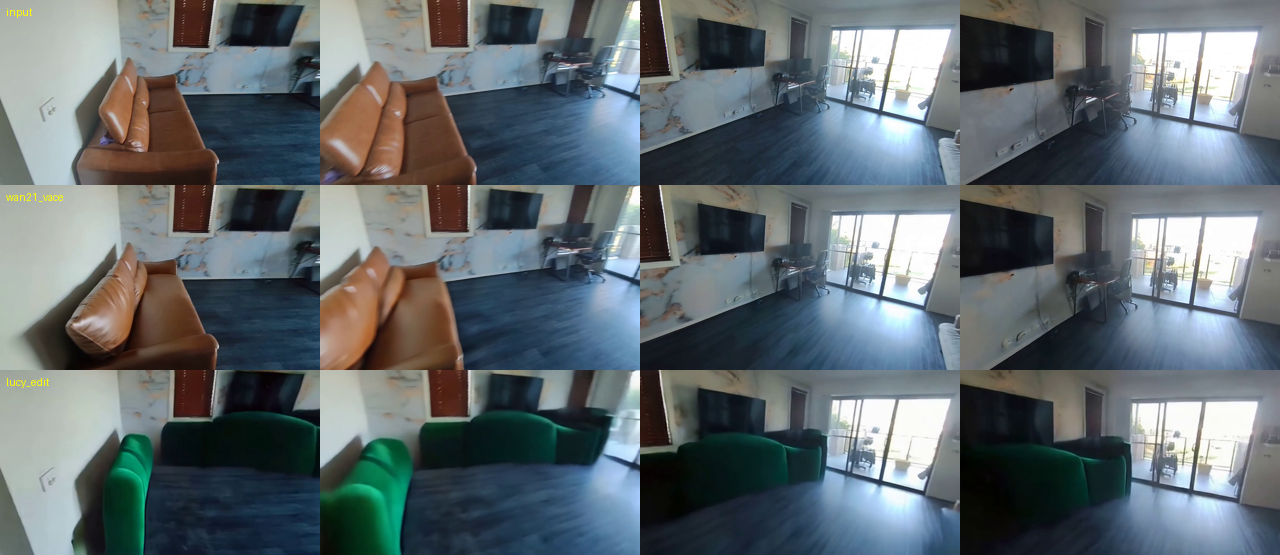

main_bedroom: (1280, 555)


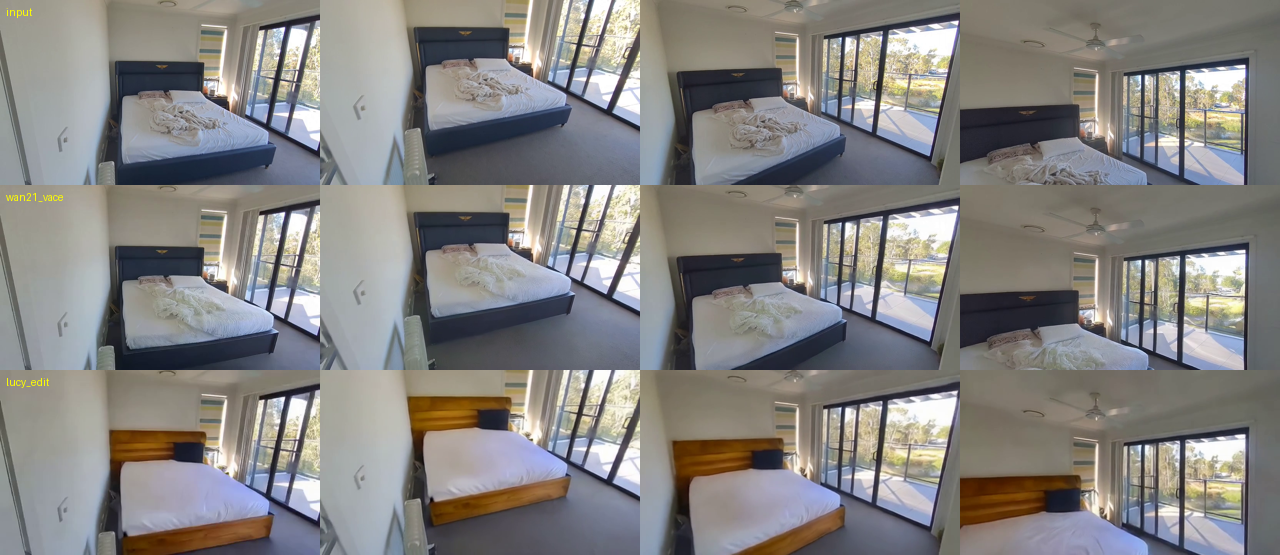

bedroom_2: (1280, 555)


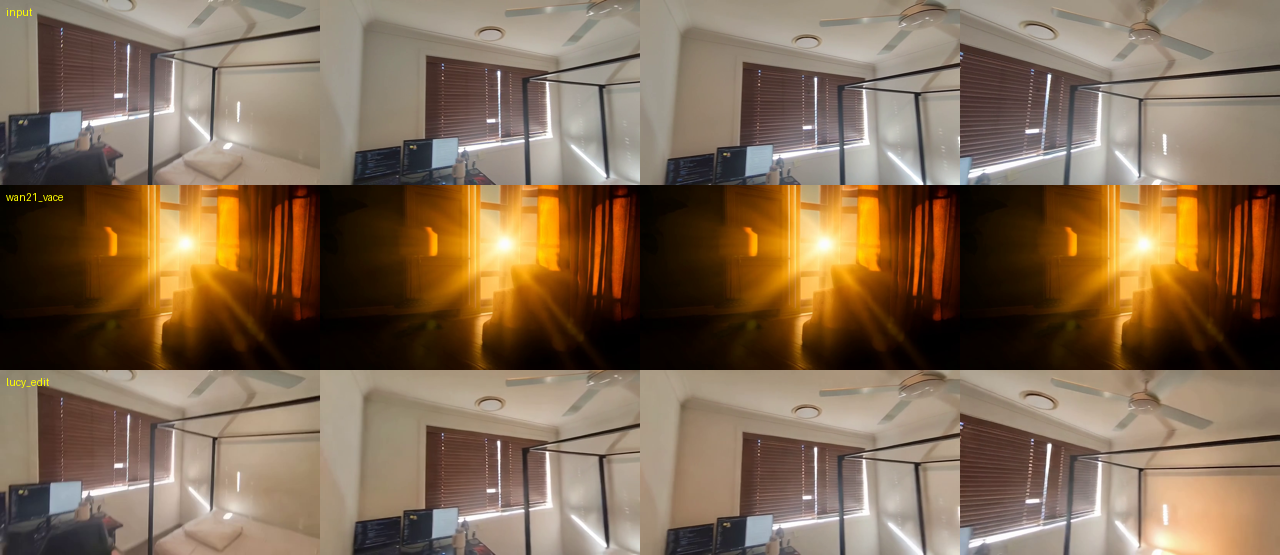

bathroom: (1280, 555)


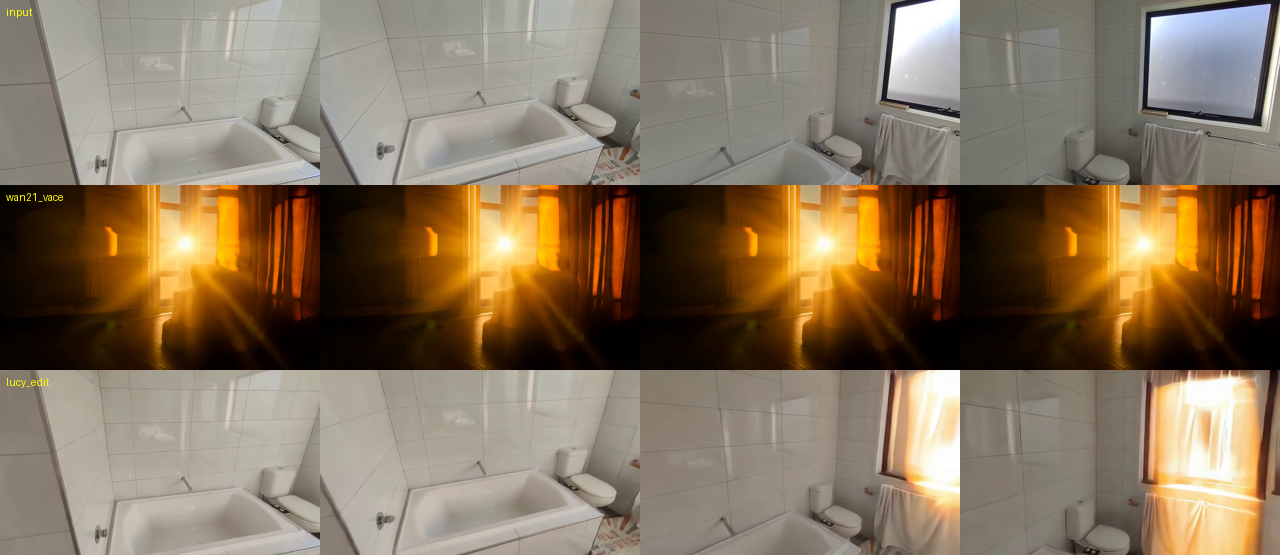

kitchen_and_main_living_area: (1280, 555)


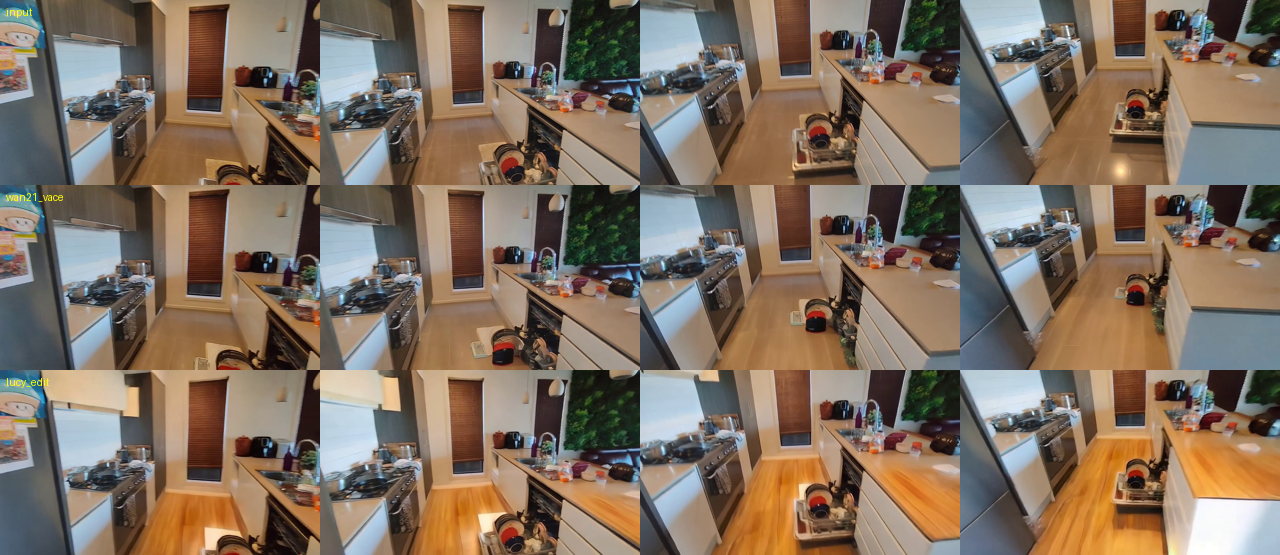

storeroom_and_gym: (1280, 555)


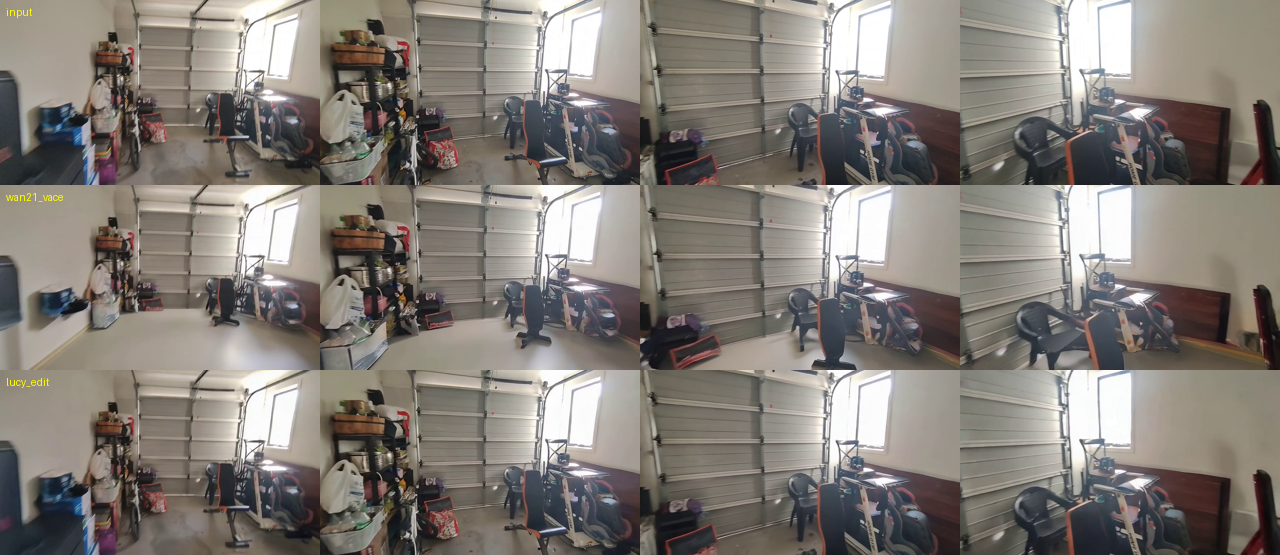

In [10]:
# [4.5] QUALITATIVE STRIPS for the report: input vs both models, 4 frames each, per item.
%cd "/content/a1/48576158 Evaluation"
import sys
import numpy as np
from pathlib import Path
from PIL import Image, ImageDraw
sys.path.insert(0, 'pairs/w7_video_editing'); sys.path.insert(0, '.')
import w7_common as C
from prepare_inputs import read_frames
out = Path('outputs/w7_figures'); out.mkdir(parents=True, exist_ok=True)
for it in C.item_ids():
    rows = []
    for label, path in [('input', C.clip_path(it))] + [(m, C.video_path(m, it, C.SEEDS[0])) for m in C.MODELS]:
        if not Path(path).exists():
            continue
        fr, _ = read_frames(Path(path))
        idx = [0, len(fr)//3, 2*len(fr)//3, len(fr)-1]
        tiles = []
        for j, i in enumerate(idx):
            im = Image.fromarray(fr[i]).resize((320, 185))
            if j == 0:
                ImageDraw.Draw(im).text((6, 6), label, fill=(255, 255, 0))
            tiles.append(np.asarray(im))
        rows.append(np.hstack(tiles))
    if rows:
        sheet = Image.fromarray(np.vstack(rows))
        sheet.save(out / f'w7_strip_{it}.jpg', quality=90)
        print(f'{it}: {sheet.size}')
        display(sheet)

## 5. Cost, shut down

In [11]:
# [5.1] COST LOG: fill in HOURS and UNITS_PER_HR (Resources panel), run once per session
%cd "/content/a1/48576158 Evaluation"
HOURS = None
UNITS_PER_HR = None
if HOURS and UNITS_PER_HR:
    from a1eval import log_cost
    log_cost('cost_log.csv', '2026-11-05', 'Colab Pro', 'A100-40GB', HOURS, UNITS_PER_HR * 0.1513,
             note='W7 video editing: Wan2.1-VACE-1.3B vs Lucy-Edit-Dev')
    !tail -4 cost_log.csv

/content/a1/48576158 Evaluation


In [12]:
# [5.2] FREE THE GPU: set AUTO_DISCONNECT = True once everything is copied to Drive
AUTO_DISCONNECT = True
if AUTO_DISCONNECT:
    from google.colab import runtime
    runtime.unassign()